### Basic Pandas Examples

In [1]:
# importing libraries

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
a = pd.Series(range(1,10))
b = pd.Series(["I","Like","to","use","Python","and","Pandas","vey","much"])
print(a,b)


0    1
1    2
2    3
3    4
4    5
5    6
6    7
7    8
8    9
dtype: int64 0         I
1      Like
2        to
3       use
4    Python
5       and
6    Pandas
7       vey
8      much
dtype: str


Length of index is 365


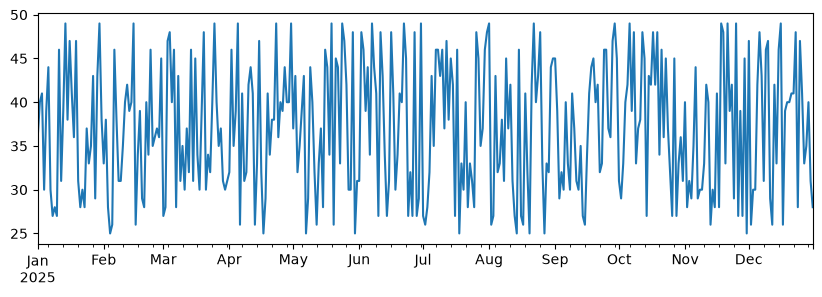

In [4]:
#Time series with pandas
start_date = "Jan 1, 2025"
end_date = "Dec 31, 2025"
idx = pd.date_range(start_date,end_date)
print(f"Length of index is {len(idx)}")

items_sold = pd.Series(np.random.randint(25,50,size=len(idx)), index=idx)
items_sold.plot(figsize=(10,3))
plt.show()

In [5]:
additional_items = pd.Series(10,index=pd.date_range(start_date,end_date,freq="W"))
print(f"Additional items (10 items each week):\n{additional_items}")
total_items = items_sold+additional_items
print(f"Total items (sum of two series):\n{total_items}")


Additional items (10 items each week):
2025-01-05    10
2025-01-12    10
2025-01-19    10
2025-01-26    10
2025-02-02    10
2025-02-09    10
2025-02-16    10
2025-02-23    10
2025-03-02    10
2025-03-09    10
2025-03-16    10
2025-03-23    10
2025-03-30    10
2025-04-06    10
2025-04-13    10
2025-04-20    10
2025-04-27    10
2025-05-04    10
2025-05-11    10
2025-05-18    10
2025-05-25    10
2025-06-01    10
2025-06-08    10
2025-06-15    10
2025-06-22    10
2025-06-29    10
2025-07-06    10
2025-07-13    10
2025-07-20    10
2025-07-27    10
2025-08-03    10
2025-08-10    10
2025-08-17    10
2025-08-24    10
2025-08-31    10
2025-09-07    10
2025-09-14    10
2025-09-21    10
2025-09-28    10
2025-10-05    10
2025-10-12    10
2025-10-19    10
2025-10-26    10
2025-11-02    10
2025-11-09    10
2025-11-16    10
2025-11-23    10
2025-11-30    10
2025-12-07    10
2025-12-14    10
2025-12-21    10
2025-12-28    10
Freq: W-SUN, dtype: int64
Total items (sum of two series):
2025-01-01     NaN

2025-01-01    36.0
2025-01-02    40.0
2025-01-03    41.0
2025-01-04    30.0
2025-01-05    49.0
              ... 
2025-12-27    33.0
2025-12-28    45.0
2025-12-29    40.0
2025-12-30    31.0
2025-12-31    28.0
Length: 365, dtype: float64


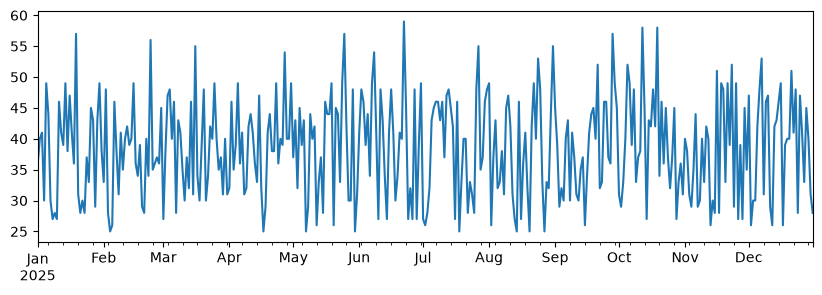

In [7]:
total_items = items_sold.add(additional_items, fill_value=0)
print(total_items)
total_items.plot(figsize=(10,3))
plt.show()

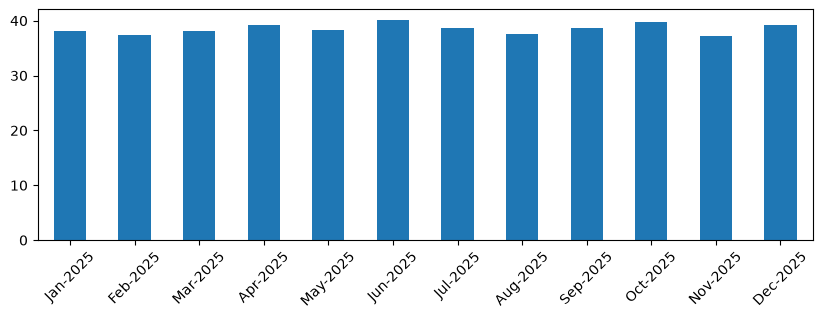

In [9]:
monthly = total_items.resample("1ME").mean()
ax = monthly.plot(kind="bar",figsize=(10,3))
ax.set_xticklabels([x.strftime("%b-%Y") for x in monthly.index], rotation=45)
plt.show()

##### DataFrame

In [10]:
df = pd.DataFrame([a,b])
df

,0,1,2,3,4,5,6,7,8
0,1,2,3,4,5,6,7,8,9
1,I,Like,to,use,Python,and,Pandas,vey,much


In [12]:
df  = pd.DataFrame({ "A":a, "B":b})
df

,A,B
0,1,I
1,2,Like
2,3,to
3,4,use
4,5,Python
5,6,and
6,7,Pandas
7,8,vey
8,9,much


In [13]:
pd.DataFrame([a,b]).T.rename(columns={0:"A",1:"B"})

,A,B
0,1,I
1,2,Like
2,3,to
3,4,use
4,5,Python
5,6,and
6,7,Pandas
7,8,vey
8,9,much


In [14]:
print(f"Column A (series):\n{df['A']}")
print(f"Columns B and A (DataFrame):\n{df[['B','A']]}")

Column A (series):
0    1
1    2
2    3
3    4
4    5
5    6
6    7
7    8
8    9
Name: A, dtype: int64
Columns B and A (DataFrame):
        B  A
0       I  1
1    Like  2
2      to  3
3     use  4
4  Python  5
5     and  6
6  Pandas  7
7     vey  8
8    much  9


In [15]:
df[df['A']<5]

,A,B
0,1,I
1,2,Like
2,3,to
3,4,use


In [17]:
df[(df['A']>5) & (df['A']<7)]

,A,B
5,6,and


In [18]:

df['DivA'] = df['A']-df['A'].mean()
df

,A,B,DivA
0,1,I,-4.0
1,2,Like,-3.0
2,3,to,-2.0
3,4,use,-1.0
4,5,Python,0.0
5,6,and,1.0
6,7,Pandas,2.0
7,8,vey,3.0
8,9,much,4.0


In [19]:
# WRONG: df['ADescr'] = "Low" if df['A'] < 5 else "Hi"
df['LenB'] = len(df['B']) # Wrong result

In [20]:
df['LenB'] = df['B'].apply(lambda x: len(x))
# or
df['LenB'] = df['B'].apply(len)
df

,A,B,DivA,LenB
0,1,I,-4.0,1
1,2,Like,-3.0,4
2,3,to,-2.0,2
3,4,use,-1.0,3
4,5,Python,0.0,6
5,6,and,1.0,3
6,7,Pandas,2.0,6
7,8,vey,3.0,3
8,9,much,4.0,4


In [21]:
df.iloc[:5]

,A,B,DivA,LenB
0,1,I,-4.0,1
1,2,Like,-3.0,4
2,3,to,-2.0,2
3,4,use,-1.0,3
4,5,Python,0.0,6


In [23]:
df.groupby(by='LenB').mean(numeric_only=True)

,A,DivA
LenB,,
1,1.0,-4.0
2,3.0,-2.0
3,6.0,1.0
4,5.5,0.5
6,6.0,1.0


In [24]:
df.groupby(by='LenB') \
 .aggregate({ 'DivA' : len, 'A' : lambda x: x.mean() }) \
 .rename(columns={ 'DivA' : 'Count', 'A' : 'Mean'})

,Count,Mean
LenB,,
1,1,1.0
2,1,3.0
3,3,6.0
4,2,5.5
6,2,6.0


In [25]:
df.head()

,A,B,DivA,LenB
0,1,I,-4.0,1
1,2,Like,-3.0,4
2,3,to,-2.0,2
3,4,use,-1.0,3
4,5,Python,0.0,6


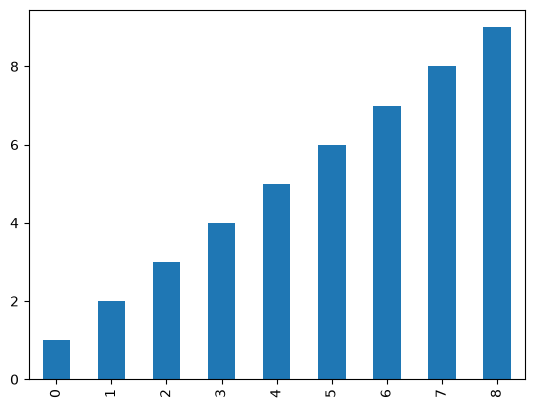

In [26]:
df['A'].plot(kind='bar')
plt.show()